# Change-Point Analysis of the ODP Site 1262 δ13C Record

## Objective
Identify statistical shifts in the bulk carbonate carbon
isotope record and evaluate their relationship to the PETM.

## Important limitations
- Change points are statistical, not automatically geological.
- Sampling gaps can influence detected transitions.
- Serial correlation can affect statistical inference.
- The published age model is treated as fixed in this exercise.

Load data

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Locate the repository
cwd = Path.cwd()

if (cwd / "data" / "raw").is_dir():
    root = cwd
elif (cwd.parent / "data" / "raw").is_dir():
    root = cwd.parent
else:
    raise FileNotFoundError("Cannot locate the project's data/raw folder.")

raw_file = root / "data" / "raw" / "208-1262_isotope.tab.tsv"

# Locate the end of the PANGAEA metadata block
with raw_file.open("r", encoding="utf-8-sig", errors="replace") as f:
    lines = f.readlines()

end_metadata = next(
    i for i, line in enumerate(lines)
    if line.strip() == "*/"
)

df = pd.read_csv(
    raw_file,
    sep="\t",
    skiprows=end_metadata + 1
)

age_col = "Age [ka BP]"
carbon_col = "δ13C bulk carb [‰ PDB]"
oxygen_col = "δ18O bulk carb [‰ PDB]"

df["age_ma"] = df[age_col] / 1000

print("Observations:", len(df))
print("Age range:", df["age_ma"].min(), "to", df["age_ma"].max())

Observations: 4364
Age range: 52.905 to 67.103


In [3]:
# Focus on the interval around the excursion
analysis = df[
    df["age_ma"].between(55.65, 56.30)
][["age_ma", carbon_col]].dropna().copy()

# Sort chronologically: older observations first
analysis = analysis.sort_values(
    "age_ma",
    ascending=False
).reset_index(drop=True)

print("Observations:", len(analysis))
display(analysis.head())

Observations: 247


,age_ma,δ13C bulk carb [‰ PDB]
0,56.299,2.915
1,56.296,2.879
2,56.293,2.901
3,56.291,2.921
4,56.288,2.925


Calculate the best single change point

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

x = analysis["age_ma"].to_numpy()
y = analysis[carbon_col].to_numpy()

n = len(y)

# Require at least 15 observations per segment
min_segment = 15

if n < 2 * min_segment:
    raise ValueError("Not enough observations for two segments.")

candidates = []

for k in range(min_segment, n - min_segment + 1):

    first = y[:k]
    second = y[k:]

    mean_first = first.mean()
    mean_second = second.mean()

    rss = (
        np.sum((first - mean_first) ** 2)
        + np.sum((second - mean_second) ** 2)
    )

    candidates.append({
        "k": k,
        "rss": rss,
        "mean_first": mean_first,
        "mean_second": mean_second,
        "older_boundary_ma": x[k - 1],
        "younger_boundary_ma": x[k]
    })

candidate_table = pd.DataFrame(candidates)

best = candidate_table.loc[
    candidate_table["rss"].idxmin()
]

display(best.to_frame(name="Value"))

,Value
k,125.000000
rss,46.771152
mean_first,2.582264
mean_second,1.521131
older_boundary_ma,55.932000
younger_boundary_ma,55.905000


Plot the detected change point

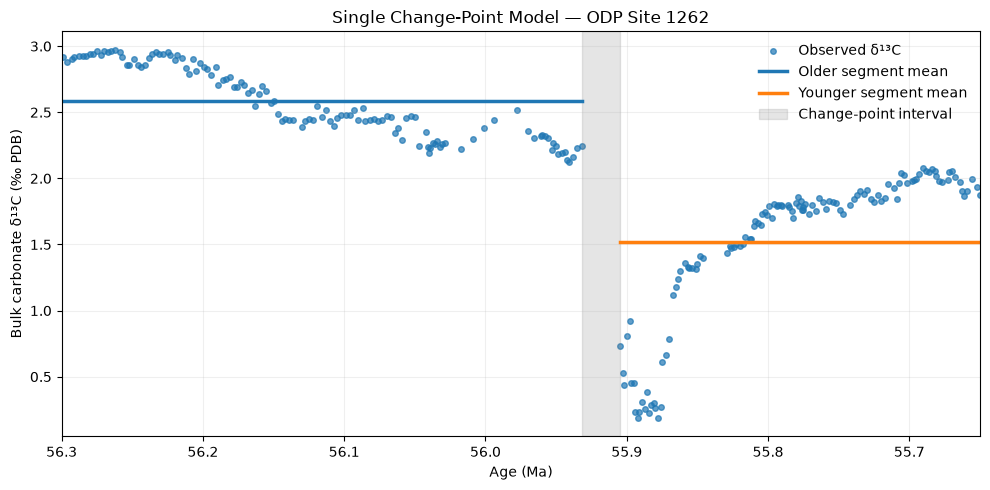

In [5]:
k = int(best["k"])

fig, ax = plt.subplots(figsize=(10, 5))

ax.scatter(
    x, y,
    s=16,
    alpha=0.7,
    label="Observed δ¹³C"
)

ax.plot(
    x[:k],
    np.full(k, best["mean_first"]),
    linewidth=2.5,
    label="Older segment mean"
)

ax.plot(
    x[k:],
    np.full(n - k, best["mean_second"]),
    linewidth=2.5,
    label="Younger segment mean"
)

# Show the sampled interval containing the boundary
ax.axvspan(
    best["younger_boundary_ma"],
    best["older_boundary_ma"],
    color="gray",
    alpha=0.2,
    label="Change-point interval"
)

ax.set_xlim(56.30, 55.65)
ax.set_xlabel("Age (Ma)")
ax.set_ylabel("Bulk carbonate δ¹³C (‰ PDB)")
ax.set_title("Single Change-Point Model — ODP Site 1262")
ax.legend(frameon=False)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

Compare against a model with no change point

In [6]:
rss_no_change = np.sum(
    (y - y.mean()) ** 2
)

rss_one_change = best["rss"]

improvement_percent = (
    (rss_no_change - rss_one_change)
    / rss_no_change
    * 100
)

print(f"No-change RSS: {rss_no_change:.3f}")
print(f"One-change RSS: {rss_one_change:.3f}")
print(f"RSS reduction: {improvement_percent:.2f}%")

No-change RSS: 116.292
One-change RSS: 46.771
RSS reduction: 59.78%


### Preliminary single change-point analysis

A single change-point model was fitted to the bulk carbonate δ¹³C record over 56.30–55.65 Ma. Observations were ordered from older to younger ages, and candidate change points were evaluated by minimizing the combined within-segment residual sum of squares.

A minimum segment size of 15 observations was imposed to prevent the model from selecting extremely short segments.

The model identifies the strongest two-mean partition within the selected interval. Its fitted boundary is interpreted as a statistical transition rather than a definitive geological PETM onset.

The model assumes piecewise-constant means and does not explicitly account for irregular temporal spacing, serial correlation, analytical uncertainty, or age-model uncertainty. Consequently, its results are treated as exploratory and will be evaluated using more flexible segmented models and sensitivity analyses.

Fit one-, two-, and three-segment models

In [7]:
import numpy as np
import pandas as pd

# Reuse the age-ordered isotope values from Lesson 10
n = len(y)
min_segment = 15

def segment_rss(values):
    """Residual sum of squares around the segment mean."""
    return np.sum((values - values.mean()) ** 2)

# Model 1: one mean, no change point
rss_1 = segment_rss(y)

# Model 2: two means, one change point
best_2 = {"rss": np.inf, "k": None}

for k in range(min_segment, n - min_segment + 1):
    rss = segment_rss(y[:k]) + segment_rss(y[k:])

    if rss < best_2["rss"]:
        best_2 = {"rss": rss, "k": k}

# Model 3: three means, two change points
best_3 = {"rss": np.inf, "k1": None, "k2": None}

for k1 in range(min_segment, n - 2 * min_segment + 1):
    for k2 in range(k1 + min_segment, n - min_segment + 1):

        rss = (
            segment_rss(y[:k1])
            + segment_rss(y[k1:k2])
            + segment_rss(y[k2:])
        )

        if rss < best_3["rss"]:
            best_3 = {
                "rss": rss,
                "k1": k1,
                "k2": k2
            }

print("One-segment RSS:", round(rss_1, 3))
print("Two-segment RSS:", round(best_2["rss"], 3))
print("Three-segment RSS:", round(best_3["rss"], 3))

One-segment RSS: 116.292
Two-segment RSS: 46.771
Three-segment RSS: 14.968


Calculate BIC

In [8]:
def calculate_bic(rss, n, p):
    return n * np.log(rss / n) + p * np.log(n)

model_comparison = pd.DataFrame({
    "segments": [1, 2, 3],
    "rss": [
        rss_1,
        best_2["rss"],
        best_3["rss"]
    ],
    "parameters": [1, 3, 5]
})

model_comparison["bic"] = model_comparison.apply(
    lambda row: calculate_bic(
        row["rss"],
        n,
        int(row["parameters"])
    ),
    axis=1
)

display(model_comparison)

,segments,rss,parameters,bic
0,1,116.291576,1,-180.552677
1,2,46.771152,3,-394.509902
2,3,14.967903,5,-664.912668


Plot the three-segment model

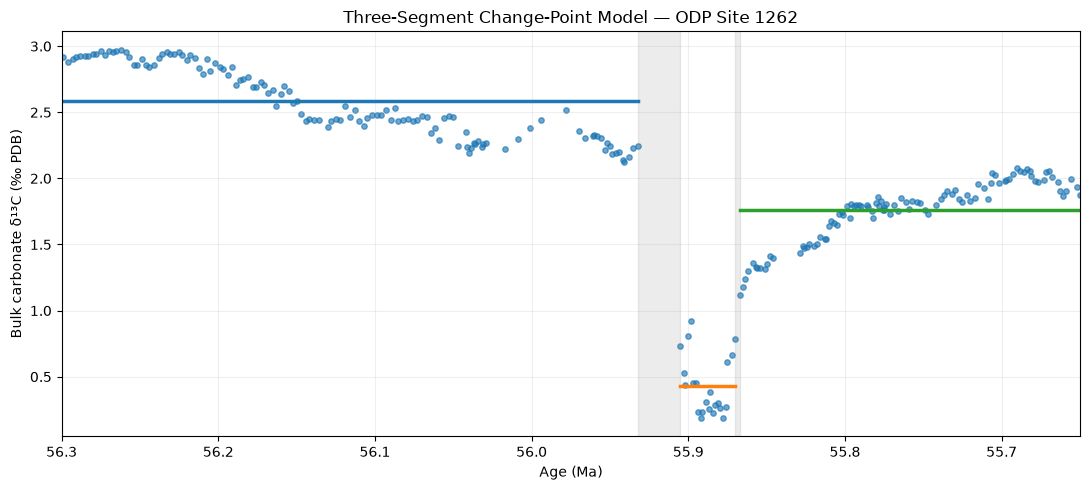

In [9]:
k1 = best_3["k1"]
k2 = best_3["k2"]

means = [
    y[:k1].mean(),
    y[k1:k2].mean(),
    y[k2:].mean()
]

fig, ax = plt.subplots(figsize=(11, 5))

ax.scatter(
    x, y,
    s=15,
    alpha=0.65,
    label="Observed δ¹³C"
)

ax.plot(x[:k1], np.full(k1, means[0]), linewidth=2.5)
ax.plot(x[k1:k2], np.full(k2-k1, means[1]), linewidth=2.5)
ax.plot(x[k2:], np.full(n-k2, means[2]), linewidth=2.5)

for k in [k1, k2]:
    ax.axvspan(
        x[k],
        x[k-1],
        color="gray",
        alpha=0.15
    )

ax.set_xlim(56.30, 55.65)
ax.set_xlabel("Age (Ma)")
ax.set_ylabel("Bulk carbonate δ¹³C (‰ PDB)")
ax.set_title("Three-Segment Change-Point Model — ODP Site 1262")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

Report the breakpoint intervals and segment means

In [10]:
segment_summary = pd.DataFrame({
    "segment": ["Older", "Middle", "Younger"],
    "n": [k1, k2-k1, n-k2],
    "mean_d13c": means
})

display(segment_summary)

print(
    "First breakpoint interval:",
    x[k1-1], "to", x[k1], "Ma"
)

print(
    "Second breakpoint interval:",
    x[k2-1], "to", x[k2], "Ma"
)

,segment,n,mean_d13c
0,Older,125,2.582264
1,Middle,22,0.432591
2,Younger,100,1.760610


First breakpoint interval: 55.932 to 55.905 Ma
Second breakpoint interval: 55.87 to 55.867 Ma


Test different minimum segment sizes

In [11]:
def find_three_segments(y, min_segment):
    n = len(y)

    best = {
        "rss": np.inf,
        "k1": None,
        "k2": None
    }

    for k1 in range(min_segment, n - 2 * min_segment + 1):
        for k2 in range(k1 + min_segment, n - min_segment + 1):

            rss = (
                segment_rss(y[:k1])
                + segment_rss(y[k1:k2])
                + segment_rss(y[k2:])
            )

            if rss < best["rss"]:
                best = {
                    "rss": rss,
                    "k1": k1,
                    "k2": k2
                }

    return best


sensitivity_results = []

for minimum in [10, 15, 20, 25, 30]:

    result = find_three_segments(y, minimum)

    sensitivity_results.append({
        "min_segment": minimum,
        "rss": result["rss"],
        "first_older_ma": x[result["k1"] - 1],
        "first_younger_ma": x[result["k1"]],
        "second_older_ma": x[result["k2"] - 1],
        "second_younger_ma": x[result["k2"]]
    })

segment_sensitivity = pd.DataFrame(sensitivity_results)

display(segment_sensitivity)

,min_segment,rss,first_older_ma,first_younger_ma,second_older_ma,second_younger_ma
0,10,14.967903,55.932,55.905,55.870,55.867
1,15,14.967903,55.932,55.905,55.870,55.867
2,20,14.967903,55.932,55.905,55.870,55.867
3,25,15.387495,55.932,55.905,55.864,55.862
4,30,17.009548,55.932,55.905,55.854,55.851


Visualize breakpoint sensitivity

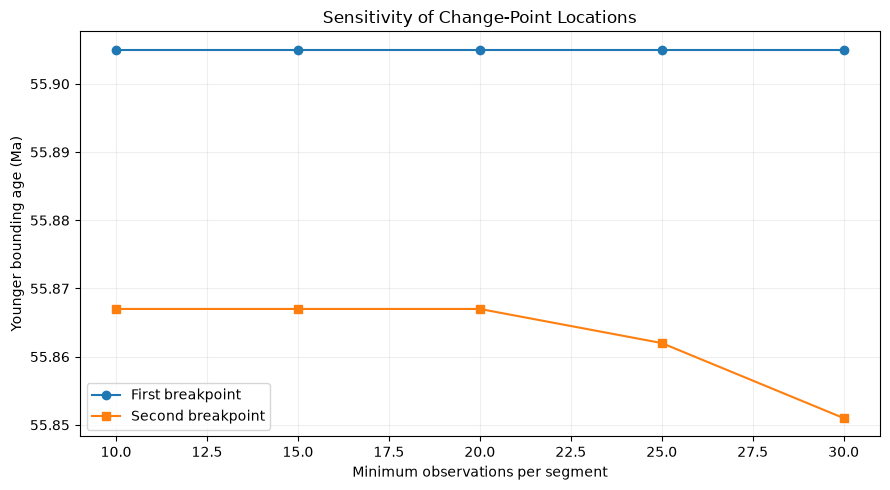

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    segment_sensitivity["min_segment"],
    segment_sensitivity["first_younger_ma"],
    marker="o",
    label="First breakpoint"
)

ax.plot(
    segment_sensitivity["min_segment"],
    segment_sensitivity["second_younger_ma"],
    marker="s",
    label="Second breakpoint"
)

ax.set_xlabel("Minimum observations per segment")
ax.set_ylabel("Younger bounding age (Ma)")
ax.set_title("Sensitivity of Change-Point Locations")

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

Save robustness results

In [18]:
from pathlib import Path

# Find the project folder
cwd = Path.cwd()

if (cwd / "data").is_dir():
    root = cwd
elif (cwd.parent / "data").is_dir():
    root = cwd.parent
else:
    raise FileNotFoundError("Project folder not found.")

# Define the results folder
results_dir = root / "results"

# Create it if it does not already exist
results_dir.mkdir(parents=True, exist_ok=True)

print("Results folder:", results_dir)

Results folder: c:\MPHIL work\paleocene eocene plaeoclimate statistics\paleocene-eocene-paleoclimate-statistics\results


In [19]:
segment_sensitivity.to_csv(
    results_dir / "change_point_min_segment_sensitivity.csv",
    index=False
)

print("Sensitivity results saved successfully!")

Sensitivity results saved successfully!
